In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch.utils.data import Dataset
from torch.utils.data import DataLoader

In [2]:
# 1. Baca train dan test dari file NPZ.
with np.load("data/mnist.npz", allow_pickle=False) as data:
    print("Array dalam NPZ:", data.files)

    x_train_original = data["x_train"]
    y_train_original = data["y_train"]
    x_test = data["x_test"]
    y_test = data["y_test"]

# Periksa ukuran dataset MNIST standar.
if x_train_original.shape != (60000, 28, 28):
    raise ValueError("Training harus berukuran (60000, 28, 28).")

if x_test.shape != (10000, 28, 28):
    raise ValueError("Test harus berukuran (10000, 28, 28).")

Array dalam NPZ: ['x_test', 'x_train', 'y_train', 'y_test']


In [3]:
# 2. Normalisasi piksel dari 0–255 menjadi 0–1.
x_train_original = x_train_original.astype(np.float32) / 255.0
x_test = x_test.astype(np.float32) / 255.0

# Tambahkan satu kanal karena gambar grayscale.
# Bentuk berubah dari (N, 28, 28) menjadi (N, 28, 28, 1).
x_train_original = x_train_original[..., np.newaxis]
x_test = x_test[..., np.newaxis]

In [4]:
# 3. Acak indeks training saja.
# Seed tetap menghasilkan pembagian yang sama saat dijalankan ulang.
rng = np.random.default_rng(seed=42)
indices = rng.permutation(len(x_train_original))

n_train = int(0.9 * len(indices))
train_indices = indices[:n_train]
val_indices = indices[n_train:]

# Gambar dan label menggunakan indeks yang sama.
x_train = x_train_original[train_indices]
y_train = y_train_original[train_indices]

x_val = x_train_original[val_indices]
y_val = y_train_original[val_indices]

# Test tetap berasal dari pembagian resmi, tanpa diacak atau dicampur.

In [5]:
# 4. Tampilkan jumlah, bentuk, tipe data, dan rentang piksel.
for nama, gambar in [
    ("Latihan", x_train),
    ("Validasi", x_val),
    ("Test", x_test),
]:
    print(
        f"{nama}: {len(gambar):,} gambar | "
        f"bentuk={gambar.shape} | dtype={gambar.dtype} | "
        f"piksel=[{gambar.min():.1f}, {gambar.max():.1f}]"
    )

Latihan: 54,000 gambar | bentuk=(54000, 28, 28, 1) | dtype=float32 | piksel=[0.0, 1.0]
Validasi: 6,000 gambar | bentuk=(6000, 28, 28, 1) | dtype=float32 | piksel=[0.0, 1.0]
Test: 10,000 gambar | bentuk=(10000, 28, 28, 1) | dtype=float32 | piksel=[0.0, 1.0]


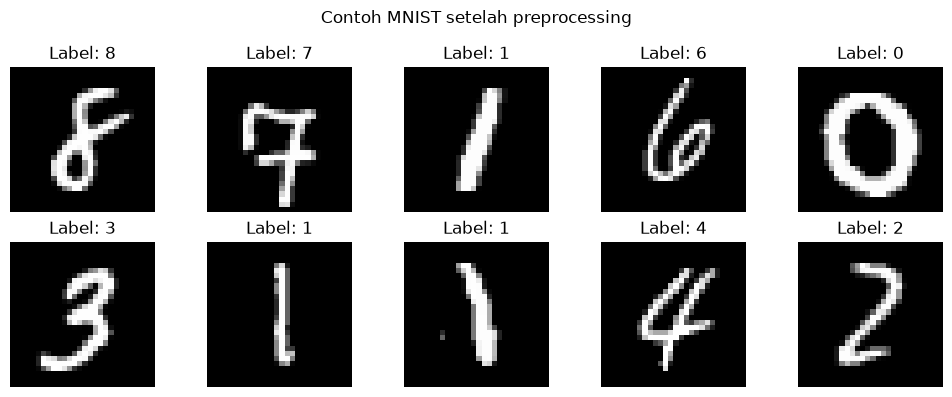

In [6]:
# 5. Tampilkan 10 contoh gambar latihan setelah preprocessing.
fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for i, ax in enumerate(axes.flat):
    ax.imshow(x_train[i, :, :, 0], cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Label: {y_train[i]}")
    ax.axis("off")

fig.suptitle("Contoh MNIST setelah preprocessing")
plt.tight_layout()
plt.show()

In [7]:
# 6. Buat PyTorch Dataset.
# Data sebelumnya masih berupa NumPy array dengan bentuk (N, 28, 28, 1).
# PyTorch menggunakan format channel-first, yaitu (N, C, H, W).
# Karena MNIST adalah gambar grayscale, jumlah kanalnya adalah 1.
class MNISTDataset(Dataset):
    def __init__(self, images):
        # Simpan kumpulan gambar yang sudah melalui preprocessing.
        self.images = images

    def __len__(self):
        # Kembalikan jumlah gambar dalam dataset.
        return len(self.images)

    def __getitem__(self, index):
        # Ambil satu gambar berdasarkan indeks.
        image = self.images[index]

        # Ubah NumPy array menjadi PyTorch tensor.
        image = torch.from_numpy(image)

        # Ubah bentuk dari HWC menjadi CHW.
        # (28, 28, 1) -> (1, 28, 28)
        image = image.permute(2, 0, 1)

        return image

In [8]:
# 7. Buat dataset untuk training, validation, dan testing.

train_dataset = MNISTDataset(x_train)
val_dataset = MNISTDataset(x_val)
test_dataset = MNISTDataset(x_test)

print(f"Train      : {len(train_dataset):,} gambar")
print(f"Validasi   : {len(val_dataset):,} gambar")
print(f"Test       : {len(test_dataset):,} gambar")

Train      : 54,000 gambar
Validasi   : 6,000 gambar
Test       : 10,000 gambar


In [10]:
# 8. Periksa satu sample dari PyTorch Dataset.
# Pastikan bentuk, tipe data, dan rentang piksel sudah sesuai dengan kebutuhan model.

sample = train_dataset[0]

print(f"Shape : {sample.shape}")
print(f"Dtype : {sample.dtype}")
print(f"Min   : {sample.min().item():.1f}")
print(f"Max   : {sample.max().item():.1f}")

Shape : torch.Size([1, 28, 28])
Dtype : torch.float32
Min   : 0.0
Max   : 1.0


In [11]:
# 9. Buat DataLoader untuk training, validation, dan testing.
# DataLoader digunakan untuk mengambil data dalam bentuk batch.
# Batch size = 128 berarti model akan menerima maksimal 128 gambar dalam satu batch.

BATCH_SIZE = 128

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print(f"Batch size: {BATCH_SIZE}")

Batch size: 128


In [12]:
# 10. Periksa satu batch dari training DataLoader.
# Bentuk yang diharapkan:
# (batch_size, channel, height, width)
# (128, 1, 28, 28)

images = next(iter(train_loader))

print(f"Shape : {images.shape}")
print(f"Dtype : {images.dtype}")
print(f"Min   : {images.min().item():.1f}")
print(f"Max   : {images.max().item():.1f}")

Shape : torch.Size([128, 1, 28, 28])
Dtype : torch.float32
Min   : 0.0
Max   : 1.0


In [13]:
# 11. Periksa jumlah batch pada setiap DataLoader.
# Jumlah batch digunakan untuk memastikan seluruh data dapat dibaca melalui DataLoader.

print(f"Jumlah batch train      : {len(train_loader)}")
print(f"Jumlah batch validation : {len(val_loader)}")
print(f"Jumlah batch test       : {len(test_loader)}")

Jumlah batch train      : 422
Jumlah batch validation : 47
Jumlah batch test       : 79
